# 01 · 若依基础应用篇


## 本章来源与学习路线

本篇对应百度网盘 **`我的资源/PPT/基础应用篇.pptx`**，共 90 页，封面为“若依专题·基础应用篇”。整理日期：2026-10-09。课件预览：[基础应用篇](https://pan.baidu.com/pfile/docview?path=%2F%E6%88%91%E7%9A%84%E8%B5%84%E6%BA%90%2FPPT%2F%E5%9F%BA%E7%A1%80%E5%BA%94%E7%94%A8%E7%AF%87.pptx&fsid=345953101351244&size=10086751&view_from=personal_file&md5=49ab7771frf74b692d464b78f5141875&share=0&client=web&scene=main)。

本课件围绕 **RuoYi-Vue 后台管理系统的搭建、使用、源码阅读和二次开发** 展开。课程管理用于练习单表开发；外卖菜品管理用于练习业务模块拆分、主子表和页面定制。第 86 页展示通义灵码辅助改造页面，本篇在相应位置补充可复用的提问方式。

| 课件部分 | 页码 | 学习结果 |
| --- | --- | --- |
| 若依搭建 | 3—9 | 跑通 Spring Boot 后端与 Vue3 前端 |
| 入门案例 | 11—15 | 从课程表生成一套 CRUD 功能 |
| 功能详解 | 17—49 | 使用权限、字典、监控、任务和开发工具 |
| 项目结构 | 51—63 | 根据问题找到模块、配置和数据库表 |
| 源码阅读 | 65—79 | 解释课程列表从页面到数据库的完整链路 |
| 二次开发 | 81—89 | 新建商家模块，完成菜品主子表与页面调整 |

**阅读约定**：“课件方案”来自 PPT 正文或截图；“整理示例”将截图信息整理为便于跟练的片段；“补充 / 改进”用于解释机制或完善实现。示例按 Java 11、Vue3、Element Plus 组织。课件没有给出的源码、DDL 约束和 AI 提示词均明确标注，避免把补写内容当成原件。


## 若依的定位与版本选择

做后台管理系统时，用户、角色、菜单、登录、日志和代码生成等能力经常重复出现。**若依是提供这些通用能力的快速开发框架**，业务开发在其基础上增加数据表、接口和页面。

课件第 4—5 页列出的版本：

| 版本 | 课件技术组合 | 主要用途 |
| --- | --- | --- |
| RuoYi | Spring Boot + Bootstrap | 前后端未按本课方式分离的管理系统 |
| RuoYi-Vue | Spring Boot + Vue | 前后端分离的单体后台，本课使用 |
| RuoYi-Cloud | Spring Cloud + Vue | 微服务架构 |
| RuoYi-App | Uni-app + Vue | 移动端应用，可适配 RuoYi-Vue / RuoYi-Cloud 后端 |
| RuoYi-other | Vue3 + Element Plus + Vite 等扩展方案 | 课件对扩展版本的归类，选择时确认具体仓库 |

**RuoYi-App 没有提供独立后端代码**。选择前端时还要确认 Vue2 / Vue3 与 Element UI / Element Plus 的匹配关系。

- 后端官方地址：[y_project/RuoYi-Vue](https://gitee.com/y_project/RuoYi-Vue)。第 6 页截图显示版本为 **3.8.7**。
- 课件给出的 Vue3 扩展地址：[ys-gitee/RuoYi-Vue3](https://gitee.com/ys-gitee/RuoYi-Vue3)。第 8 页克隆截图使用另一个 Vue3 仓库，跟练应以课程配套源码和版本为准。

复现课堂时先固定版本。直接拉取仓库最新代码，可能同时改变 JDK 要求、Spring Boot 版本、前端依赖和目录结构。


## RuoYi-Vue 架构与开发环境

前后端分离后，浏览器负责页面和交互，后端提供 HTTP API；后端业务仍集中在一个 Spring Boot 应用中运行。**Maven 多模块用于组织代码，一个模块不等于一个微服务。**

```text
浏览器 → Vue3 页面 → Axios 请求 → 开发代理 → Spring Boot API
                                              ├─ MyBatis → MySQL
                                              └─ Redis：缓存、登录状态等
```

课件技术选型：Spring Boot、Spring Security、MyBatis、JWT、Vue3、Element Plus。Spring Security 处理认证授权；MyBatis 将 Java 方法映射为 SQL；JWT 是登录令牌所采用的技术之一。

| 软件 | 第 5 页列出的推荐下限 | 课程采用版本 |
| --- | --- | --- |
| JDK | ≥ 1.8 | 11 |
| MySQL | ≥ 5.7.0 | 8 |
| Redis | ≥ 3.0 | 5，课堂 Windows 环境 |
| Maven | ≥ 3.0 | 3.6 |
| Node.js | ≥ 12 | 16，课堂 Vue3 环境 |

这些是**课件所处版本的环境说明**。安装当前源码时，还需核对根 `pom.xml`、前端 `package.json` 的 `engines` 和仓库说明。JDK 同时影响 IDEA 的项目 SDK、Maven 编译和实际启动进程。


## 后端搭建：数据库、Redis 与启动类

后端能编译，仍可能因为数据库或 Redis 不可用而启动失败。课件第 6—9 页的顺序是：克隆工程 → 导入数据库 → 修改连接配置 → 启动 Redis → 运行后端。

**整理示例：**

```bash
git clone https://gitee.com/y_project/RuoYi-Vue.git
cd RuoYi-Vue
mvn clean package
```

将项目作为 Maven 工程导入 IDEA，选择 JDK 11。依赖尚未下载完整时，等待 Maven 同步；课件建议执行 `clean`、`package` 完成初始化。

第 6 页截图在 `sql/` 下展示 `ry_20231130.sql` 和 `quartz.sql`，使用数据库 `ry-vue`。先建立对应数据库，再执行配套脚本；系统脚本和 Quartz 脚本分别提供管理系统表与调度器内部表。脚本文件名以所用版本为准。

数据库连接位于 `ruoyi-admin/src/main/resources/application-druid.yml`。下面仅列需要检查的层级，合并到原配置中：

```yaml
# 整理示例；密码由本机环境变量提供
spring:
  datasource:
    druid:
      master:
        url: jdbc:mysql://localhost:3306/ry-vue?useUnicode=true&characterEncoding=utf8&serverTimezone=Asia/Shanghai
        username: root
        password: ${DB_PASSWORD:}
```

Redis 连接位于 `application.yml`。已有密码时，要同步修改项目中的密码配置：

```yaml
# 整理示例
spring:
  redis:
    host: localhost
    port: 6379
    database: 0
    password: ${REDIS_PASSWORD:}
```

最后运行 `ruoyi-admin` 中的 **`RuoYiApplication`**。课件后续请求使用后端端口 `8080`。检查启动日志中的实际端口、当前 profile，以及数据库配置文件是否被加载。

| 现象 | 优先检查 |
| --- | --- |
| Maven 解析依赖失败 | Maven 配置、仓库网络、JDK、实际错误依赖 |
| 数据库连接失败 | 服务、端口、数据库名、账号密码、脚本是否导入 |
| Redis 连接失败 | Redis 进程、端口、密码和数据库编号 |
| 端口被占用 | 当前启动实例，以及 `server.port` |


## 前端搭建：Vue3 与依赖版本

课件使用单独的 Vue3 前端工程。确认打开的是该工程根目录，再安装依赖；根目录应能看到 `package.json` 和 `vite.config.js`。

**整理示例，克隆地址采用课件正文给出的 Vue3 扩展仓库：**

```bash
git clone https://gitee.com/ys-gitee/RuoYi-Vue3.git
cd RuoYi-Vue3
npm install --registry=https://registry.npmmirror.com
npm run dev
```

> **勘误：**第 9 页写成了 `--registr`，应使用完整参数 **`--registry`**。运行命令应以当前 `package.json` 的 `scripts` 为准。

第 8 页截图可以看到 Node `v16.20.0` 与 npm `8.19.4`，同时出现 `EBADENGINE` 警告。遇到引擎版本警告，应核对依赖要求；“安装完成”只能说明依赖安装过程结束，还要确认启动和构建能正常完成。

浏览器访问终端输出的地址，完成登录并打开课程管理页面，才能证明页面、代理、后端和基础服务已经连通。课件示例前端地址是 `http://localhost`，具体端口取决于 Vite 配置。


## 课程管理：业务字段与数据库表

第 12—15 页用课程管理演示代码生成。页面需要按课程编码、学科、名称和适用人群查询，并提供新增、修改、删除、导出和分页。

课件截图中的表名是 **`tb_course`**：

| 数据库字段 | 类型 | Java 属性 | 含义 |
| --- | --- | --- | --- |
| `id` | bigint | `id` | 课程 ID，主键 |
| `code` | varchar(32) | `code` | 课程编码 |
| `subject` | varchar(32) | `subject` | 学科，后续改为字典值 |
| `name` | varchar(64) | `name` | 课程名称 |
| `price` | int | `price` | 价格，课件单位为元 |
| `applicable_person` | varchar(32) | `applicablePerson` | 适用人群 |
| `info` | varchar(255) | `info` | 课程介绍 |
| `create_time` | timestamp | `createTime` | 创建时间 |
| `update_time` | timestamp | `updateTime` | 更新时间 |

`applicable_person → applicablePerson` 是下划线字段转驼峰属性。第 15 页生成配置将 `id` 和 `price` 的 Java 类型选为 `Long`，字符串选为 `String`，时间选为 `Date`。

下面的 DDL 按截图字段重建，**主键自增、空值规则和默认时间属于整理选择，PPT 未展示完整建表 SQL**：

```sql
CREATE TABLE tb_course (
    id BIGINT NOT NULL AUTO_INCREMENT COMMENT '课程id',
    code VARCHAR(32) COMMENT '课程编码',
    subject VARCHAR(32) COMMENT '课程学科',
    name VARCHAR(64) COMMENT '课程名称',
    price INT COMMENT '价格（元）',
    applicable_person VARCHAR(32) COMMENT '适用人群',
    info VARCHAR(255) COMMENT '课程介绍',
    create_time TIMESTAMP NULL DEFAULT NULL COMMENT '创建时间',
    update_time TIMESTAMP NULL DEFAULT NULL COMMENT '更新时间',
    PRIMARY KEY (id)
) ENGINE=InnoDB DEFAULT CHARSET=utf8mb4 COMMENT='课程管理';
```

**补充：**金额字段要先确定单位与精度。本例使用整数元；后面的菜品使用 `decimal(10,2)`。新增业务若需要小数金额，可以使用 `DECIMAL` 配合 Java `BigDecimal`，并统一接口单位。

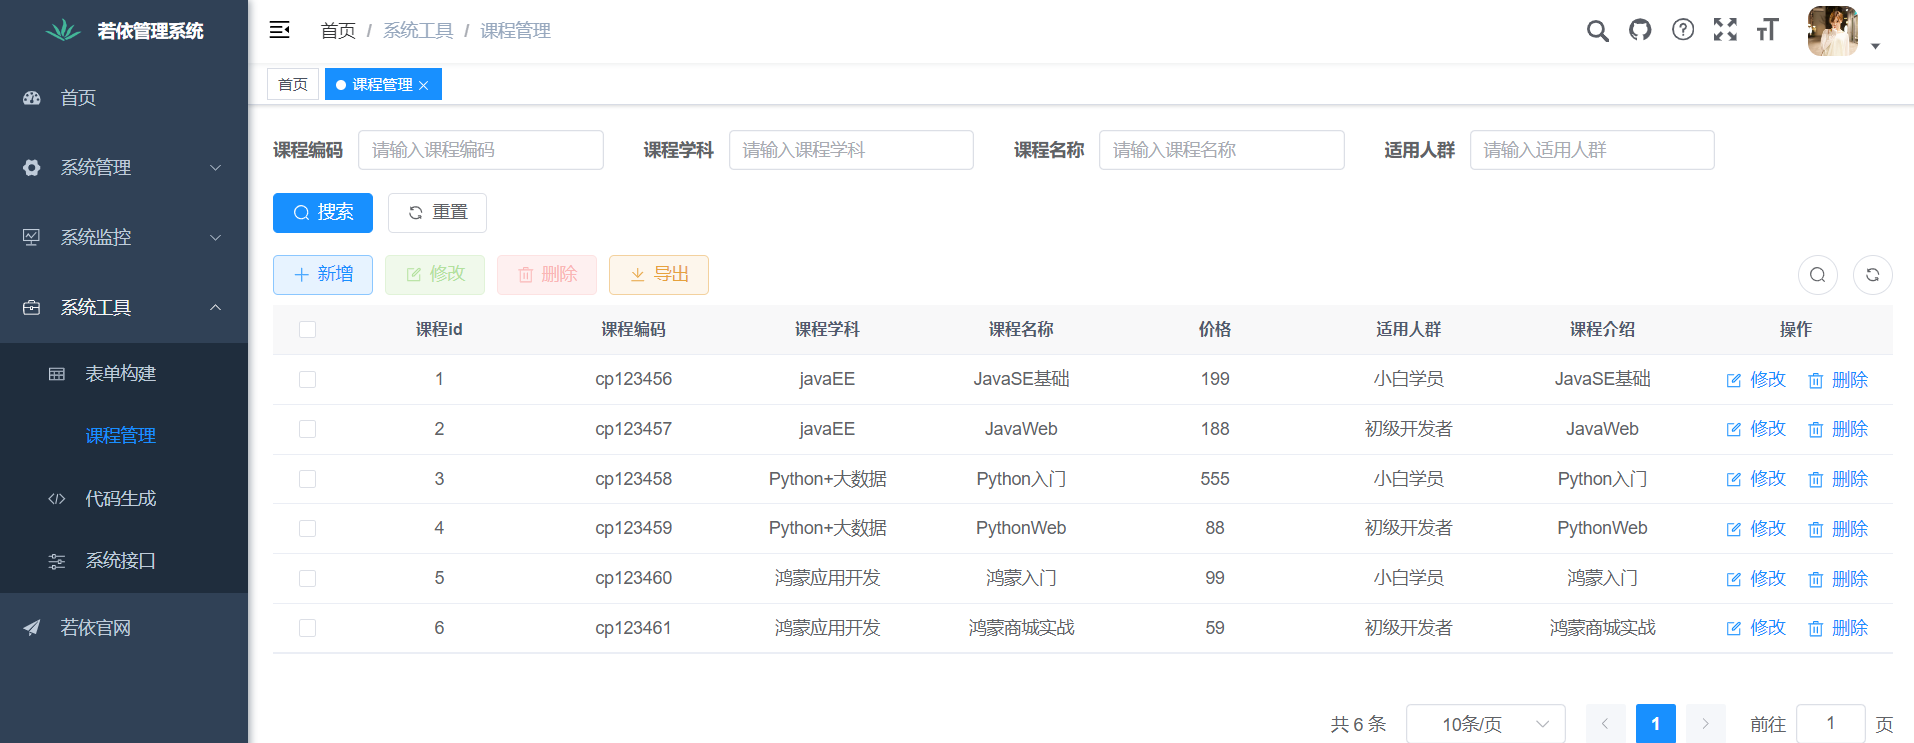


## 单表代码生成：从页面原型反推配置

代码生成器根据表结构生成 CRUD，即新增、查询、修改、删除。它能减少重复代码，生成效果取决于配置是否符合页面需求。

课件第 13—15 页的操作：导入 `tb_course` → 编辑生成信息 → 预览 → 下载代码。

| 配置区域 | 要检查的内容 | 课程案例 |
| --- | --- | --- |
| 基本信息 | 表说明、实体类名等 | 课程管理、`Course` |
| 字段信息 | Java 类型与属性 | `applicable_person → applicablePerson` |
| 字段用途 | 插入、编辑、列表、查询 | 查询项按页面原型勾选 |
| 查询方式 | 等值或模糊匹配 | 课程名称为 `LIKE`；编码、学科等为等值 |
| 显示类型 | 文本框、下拉框、日期控件等 | 学科改造后选择下拉框并绑定字典 |
| 生成信息 | 模板、包路径、模块名、业务名、上级菜单 | 单表模板；生成课程管理菜单与权限 |
| 前端类型 | 对应的 Vue 和组件库模板 | Vue3 / Element Plus |

课程路径最终为 `/course/course`：生成模块名和业务名都使用 `course`，所以出现两段 `course`。包名、接口路径、页面路径和权限前缀需要一起核对。

**整理建议：**主键交给数据库生成；创建时间、更新时间由后端维护；业务字段按新增与编辑需求勾选。是否必填还需要与后端校验、数据库约束配合，不能只依赖页面上的红色星号。

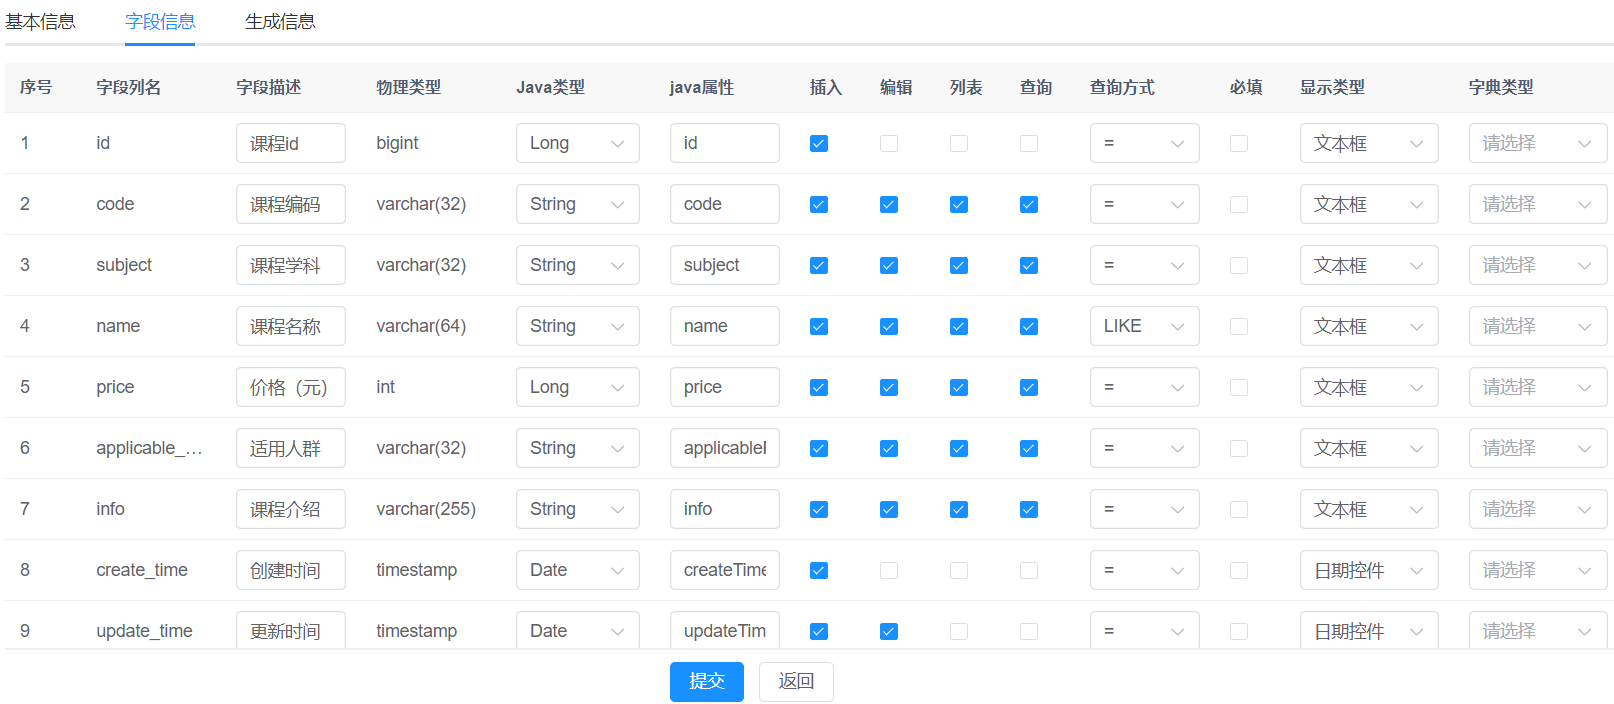


## 生成产物导入与功能验收

下载压缩包后，需要分别接入 Java、Mapper XML、前端代码与菜单 SQL。课件第 14 页中压缩包包含 `main/`、`vue/` 和 `courseMenu.sql`。

```text
后端 ruoyi-admin/src/main/
├─ java/com/ruoyi/course/
│  ├─ controller/CourseController.java
│  ├─ domain/Course.java
│  ├─ mapper/CourseMapper.java
│  └─ service/
│     ├─ ICourseService.java
│     └─ impl/CourseServiceImpl.java
└─ resources/mapper/course/CourseMapper.xml

Vue3 前端 src/
├─ api/course/course.js
└─ views/course/course/index.vue

数据库：执行 courseMenu.sql，写入 sys_menu
```

入门案例把课程相关后端代码放进 `ruoyi-admin`。二次开发部分再演示如何将业务放进独立子模块。

1. 按包路径复制 Java 文件，把 XML 放进能被 MyBatis 扫描的位置。
2. 复制前端 API 文件与页面，保留生成时的目录层级。
3. 执行菜单 SQL；检查组件路径、上级菜单、权限标识。
4. 重启后端、刷新前端；普通用户还要通过角色获得菜单和按钮权限。
5. 验证查询、分页、新增、修改、删除和导出，并检查浏览器 Network 中的真实请求。

**补充：**重新生成前先查看差异。字典展示、页面布局或业务校验已经手工修改时，直接覆盖文件会丢失这些改动；菜单 SQL 重复执行也可能产生重复记录。


## RBAC：用户通过角色获得权限

直接给每个用户逐项配置权限，人员多时很难维护。课件第 19—25 页使用 **RBAC（Role-Based Access Control，基于角色的访问控制）**：先把权限分给角色，再把角色分给用户。

```text
小智 ── 用户关联角色 ──→ 课研人员 ── 角色关联权限 ──→ 课程管理、统计分析
小灰 ── 用户关联角色 ──→ 市场专员 ── 角色关联权限 ──→ 线索管理、活动管理
小白 ── 用户关联角色 ──→ 销售专员 ── 角色关联权限 ──→ 商机管理、合同管理
```

课件通过 CRM 页面展示不同角色看到不同菜单。关键是维护三类对象和两组多对多关系：一个用户可以有多个角色，一个角色可以对应多个用户；角色和菜单权限也通过关联表连接。

| 表 | 职责 |
| --- | --- |
| `sys_user` | 用户信息 |
| `sys_role` | 角色信息 |
| `sys_menu` | 菜单与按钮权限 |
| `sys_user_role` | 用户—角色关系 |
| `sys_role_menu` | 角色—菜单权限关系 |
| `sys_dept` | 部门信息，用户归属部门 |
| `sys_post` | 岗位信息 |
| `sys_user_post` | 用户—岗位关系 |
| `sys_role_dept` | 角色—部门关系，用于配置数据范围 |

**补充：**功能权限决定“能否调用某个功能”，数据权限决定“能看哪些记录”。部门、岗位、角色分别表达组织归属、职位和授权身份。配置角色部门范围后，还需业务查询接入相应的数据权限机制。

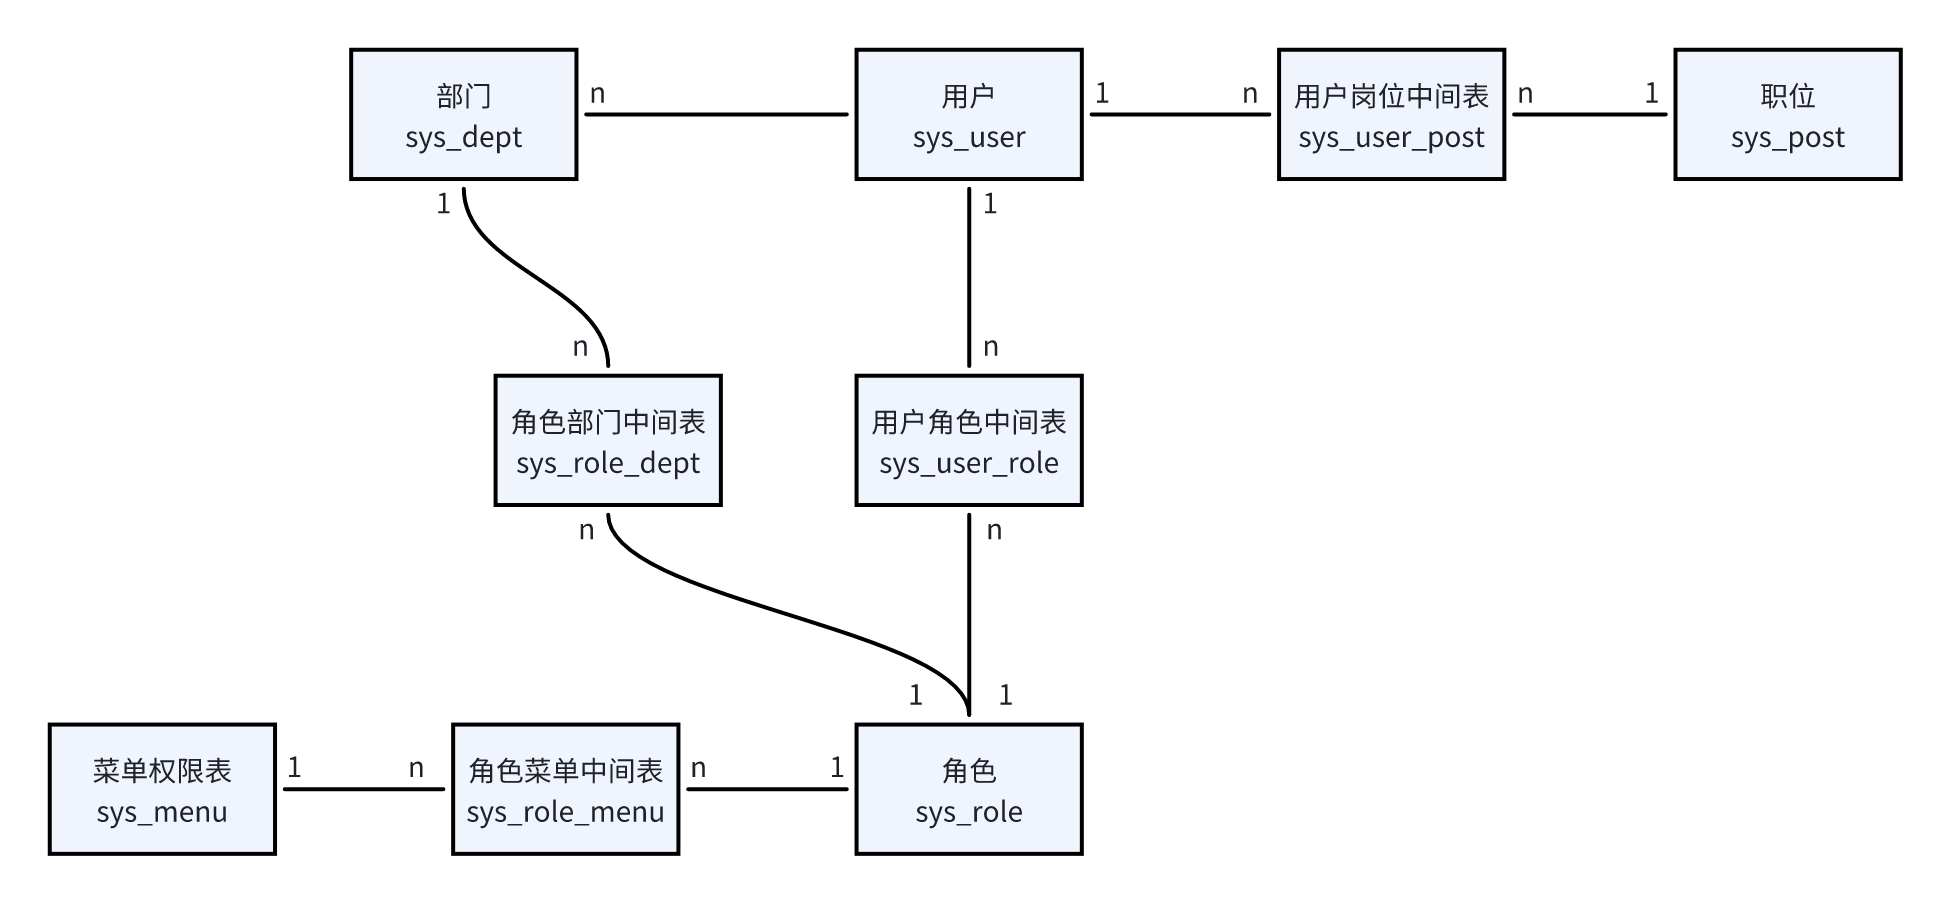


## 授权实践：小智只能访问课程管理和统计分析

课件第 24—25 页要求创建用户“小智”，关联“课研人员”角色，并授予课程管理、统计分析菜单。

1. 在菜单管理中创建或确认业务菜单、页面组件路径和按钮权限。
2. 创建“课研人员”角色，勾选相应菜单及需要的操作权限。
3. 创建“小智”用户，关联该角色；重新登录后检查页面。
4. 用该普通用户验证允许访问的功能，同时验证未授权的接口会被后端拒绝。

菜单管理中的类型决定记录的作用：

| 类型 | 作用 | 需要关注 |
| --- | --- | --- |
| 目录 | 组织下级菜单 | 上级目录、显示顺序 |
| 菜单 | 指向业务页面 | 路由地址、组件路径、权限标识 |
| 按钮 | 表达页面内某项操作权限 | 新增、修改、删除等权限字符串 |

第 73 页课程权限示例：

| 操作 | 权限标识 |
| --- | --- |
| 列表 | `course:course:list` |
| 查询详情 | `course:course:query` |
| 新增 | `course:course:add` |
| 修改 | `course:course:edit` |
| 删除 | `course:course:remove` |
| 导出 | `course:course:export` |

**补充：**前端根据权限显示菜单和按钮，后端独立校验请求权限。只隐藏按钮仍可被直接调用接口；完整授权需要菜单配置、角色分配、前端控制和后端注解保持一致。只授予列表权限时，也要明确是否允许查看详情或修改，按业务需要分别配置。


## 数据字典：把学科名称与存储值分开

性别、启用状态、课程学科等选项会反复出现在查询框、编辑表单和列表中。课件第 27—30 页用**数据字典**集中维护这些枚举选项，包含字典类型和字典数据两部分。

| 表 | 保存什么 | 关键字段 |
| --- | --- | --- |
| `sys_dict_type` | 一组字典的定义，例如“学科” | `dict_type`：类型标识 |
| `sys_dict_data` | 组内每个选项的标签、值、排序和状态 | `dict_type`、`dict_label`、`dict_value` |

一个字典类型对应多条字典数据。这里按 `dict_type` 类型字符串归组，具体数据库是否建立物理外键要查看建表脚本。

第 30 页新增字典 **`course_subject`**：

| 字典标签：给用户看 | 字典值：业务表存储 |
| --- | --- |
| JavaEE | `0` |
| Python+大数据 | `1` |
| 鸿蒙应用开发 | `2` |

课件操作顺序：新增字典类型和数据 → 在代码生成器中把 `subject` 改为下拉框并选择“学科”字典 → 下载代码 → 更新前端。

**整理示例：Vue3 中的字典加载和展示片段。**使用若依现有的字典插件及组件，在已有页面中接入：

```vue
<script setup>
import { getCurrentInstance } from 'vue'
const { proxy } = getCurrentInstance()
const { course_subject } = proxy.useDict('course_subject')
// form 使用生成页面中已有的表单对象
</script>

<template>
  <el-select v-model="form.subject" placeholder="请选择学科">
    <el-option
      v-for="item in course_subject"
      :key="item.value"
      :label="item.label"
      :value="item.value"
    />
  </el-select>
  <!-- 列表列的插槽中使用： -->
  <!-- <dict-tag :options="course_subject" :value="scope.row.subject" /> -->
</template>
```

**补充：**`subject` 是字符串字段，接口值、下拉框值和字典值应统一为字符串，例如 `"0"`。已有业务数据如果仍保存 `JavaEE` 等名称，要先完成映射迁移；否则新页面可能显示原始值或无法选中。字典变更后还要检查缓存刷新和旧值兼容。

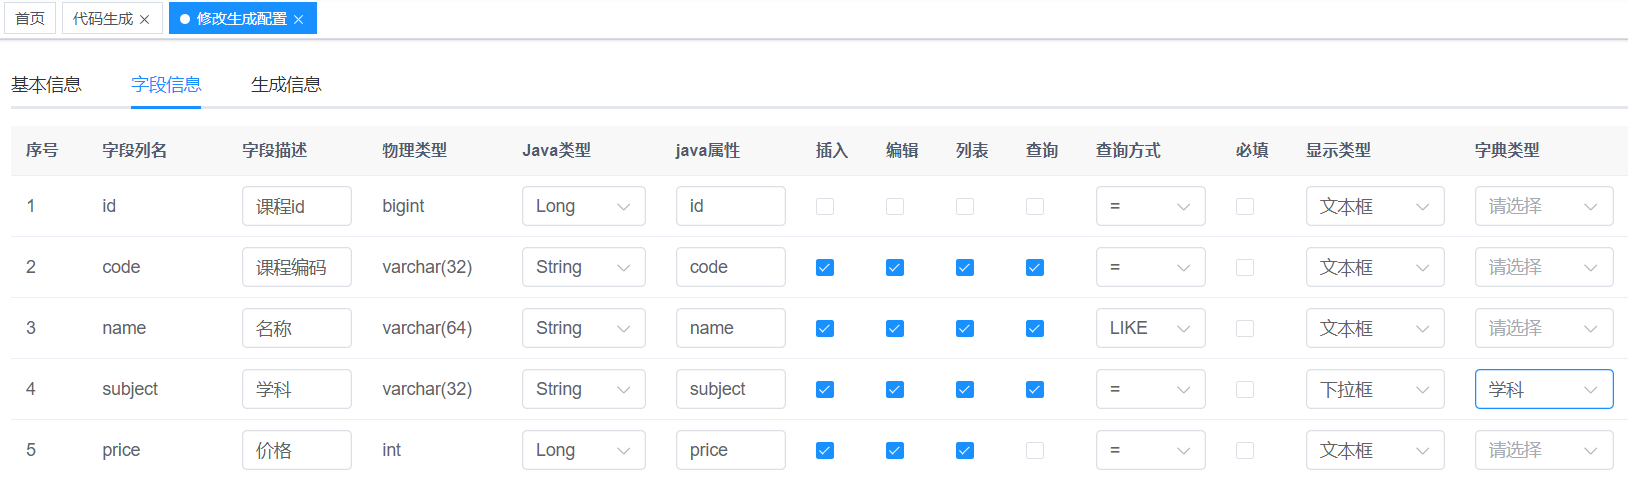


## 系统管理：参数、公告与日志

有些系统行为需要运维人员动态修改，另一些信息需要发布或追溯。课件第 32—34 页介绍三组能力：

| 功能 | 用途 | 相关表 |
| --- | --- | --- |
| 参数设置 | 动态维护已有代码会读取的参数 | `sys_config` |
| 通知公告 | 发布组织内部消息 | `sys_notice` |
| 登录日志 | 追踪登录和访问结果 | `sys_logininfor` |
| 操作日志 | 记录用户执行业务操作的情况 | `sys_oper_log` |

第 32 页示例参数是 **`sys.account.captchaEnabled`**，值 `true` 表示开启登录验证码，`false` 表示关闭。

**补充：**增加一条参数记录后，需要业务代码按参数键读取它，才能产生效果。操作日志通常由若依的日志注解与 AOP 接入；AOP 会在方法周围统一执行记录逻辑。登录日志、操作日志和控制台错误日志分别用于追踪身份访问、业务操作与程序故障。


## 系统监控：先判断故障在哪一层

课件第 36 页展示在线用户、服务监控、缓存监控，并在菜单中列出数据监控、缓存列表等工具。监控数据用于定位当前状态，判断后还需回到对应日志或请求证据。

| 工具 | 可观察的内容 | 典型用途 |
| --- | --- | --- |
| 在线用户 | 登录会话、用户、登录地址等 | 检查会话和执行强退 |
| 服务监控 | CPU、系统内存、JVM、服务器信息 | 判断应用是否受资源限制 |
| 缓存监控 | Redis 信息、命令统计、内存占用 | 检查缓存服务状态 |
| 缓存列表 | 缓存分类与数据 | 查看目标缓存是否存在 |
| 数据监控 | 数据源、SQL 等信息，取决于配置 | 检查数据库访问与慢 SQL |

**补充：**系统总内存与 JVM 堆内存是不同指标。接口变慢时，先确认请求是否到达后端，再结合耗时、SQL、CPU、JVM 和 Redis 状态定位，避免只看一张监控图就下结论。


## 定时任务：Spring 注解与若依动态调度

定时任务让程序按时间规则运行。课件第 38—39 页比较代码中固定配置的 `@Scheduled` 与若依界面中维护的任务。若依的任务模块使用 Quartz 调度器，支持新增、启停、立即执行和查看日志。

| 方式 | 时间规则放在哪里 | 适合场景 |
| --- | --- | --- |
| Spring `@Scheduled` | 源码注解 | 随版本发布的固定任务 |
| 若依定时任务 | 管理页面与数据库 | 需要动态调整规则或启停的任务 |

**课件方案：每 5 秒输出一次时间。**在 `ruoyi-quartz` 中创建类：

```java
package com.ruoyi.quartz.task;

import org.springframework.stereotype.Component;
import java.util.Date;

@Component
public class MyTask {
    public void showTime() {
        System.out.println("定时任务开始执行：" + new Date());
    }
}
```

在“系统监控 → 定时任务”中新增：

| 项目 | 课件配置 |
| --- | --- |
| 任务名称 | 输出时间 |
| 调用方法 | `myTask.showTime()` |
| Cron 表达式 | `0/5 * * * * ?` |
| 是否并发 | 禁止 |
| 任务状态 | 启用 |

`@Component` 让 Spring 管理 `MyTask`，默认 Bean 名为 `myTask`。任务调用目标使用 Bean 名和方法名。`sys_job` 保存业务任务配置，`sys_job_log` 保存执行日志；Quartz 内部调度数据另有 `qrtz_*` 表。

> **勘误与补充：**第 38 页 `@Scheduled` 示例存在字段数、空格问题。Spring Cron 使用六个字段：秒、分、时、日、月、周，可写为 `@Scheduled(cron = "0/5 * * * * ?")`，并启用 `@EnableScheduling`。Quartz 可以使用六个字段或增加第七个“年”字段。使用若依界面调度本例时，方法只保留业务代码，避免再添加 `@Scheduled` 导致两个调度入口重复执行。

界面还提供错过触发时间后的执行策略，以及是否允许并发。**补充：**长任务需要明确并发行为；会修改数据的任务应考虑幂等，即重复执行仍得到正确结果。

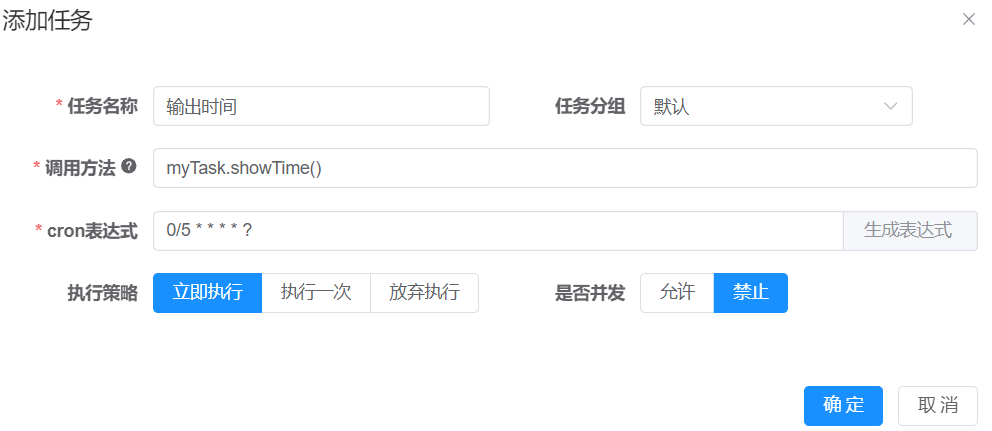


## 表单构建：拖拽页面与接入接口

课件第 41—43 页的表单构建器通过拖拽生成 Vue 表单。它负责布局、组件和表单规则，生成后还要接入业务接口。

课堂操作：制作添加课程表单 → 导出 → 复制到前端 → 创建动态菜单。

| 项目 | 第 43 页示例 |
| --- | --- |
| 页面文件 | `src/views/course/course/add.vue` |
| 菜单名称 | 添加课程 |
| 路由地址 | `course/add` |
| 组件路径 | `course/course/add`，相对于 `src/views`，省略 `.vue` |

表单中除了编码、学科、名称、价格、人群、介绍，还出现有效期、课程封面、推荐指数。**补充：**新增表单字段要同步核对后端实体、接口和数据库；上传控件需要上传接口，提交按钮需要保存接口。

导出时可以选择页面或弹窗。课件截图展示了类型选择框；实际接入独立菜单时，应保证导出的组件能作为独立页面使用。还要核对导出代码是否适用于 Vue3 和 Element Plus，再接入项目。

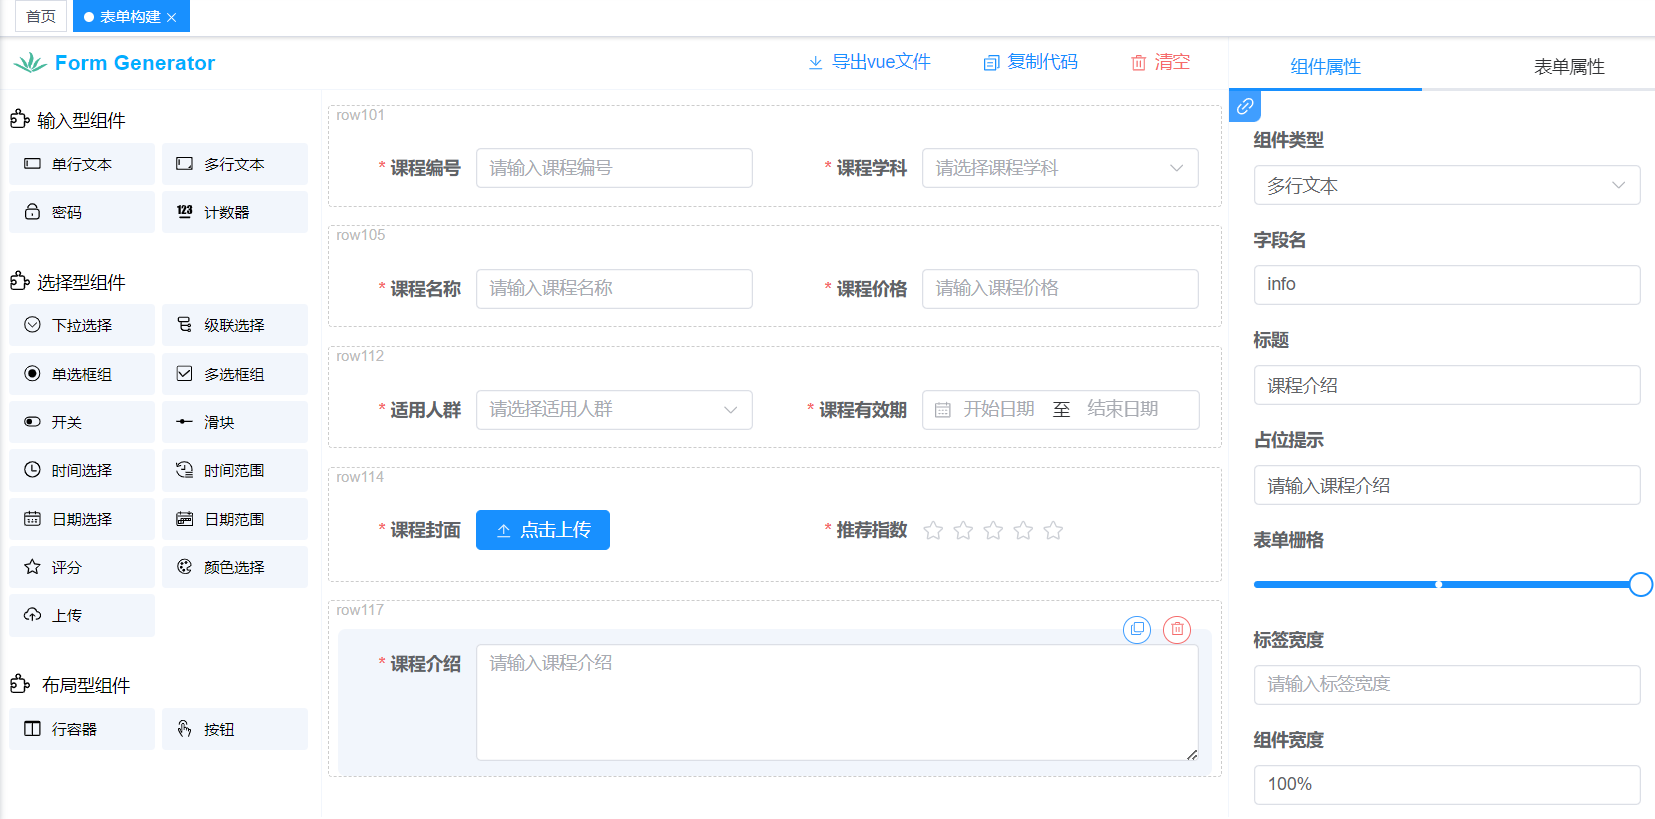


## 代码生成模板：单表、树表与主子表

不同数据关系需要不同页面与保存逻辑。课件第 45—46 页提供三种模板：

| 模板 | 数据关系 | 案例 | 关键配置 |
| --- | --- | --- | --- |
| 单表 | 一条业务记录独立保存 | 课程管理 | 主键和普通字段 |
| 树表 | 同一表内记录存在父子层级 | 部门、分类 | 节点 ID、父节点 ID、节点名称 |
| 主子表 | 一条主记录带多条明细 | 菜品与口味 | 子表、子表关联外键 |

课件树表案例使用部门表：`dept_id` 是节点 ID，`parent_id` 是父节点 ID，`dept_name` 是节点名称；`ancestors` 保存祖先路径。

```text
若依科技（100，parent_id=0）
├─ 深圳总公司（101，parent_id=100）
│  ├─ 研发部门（103，parent_id=101）
│  └─ 市场部门（104，parent_id=101）
└─ 长沙分公司（102，parent_id=100）
```

**补充：**修改父节点时要防止把节点挂到自己或自己的后代下面；删除时明确是否允许存在子节点。主子表涉及两张表，其事务与明细维护在菜品案例中展开。

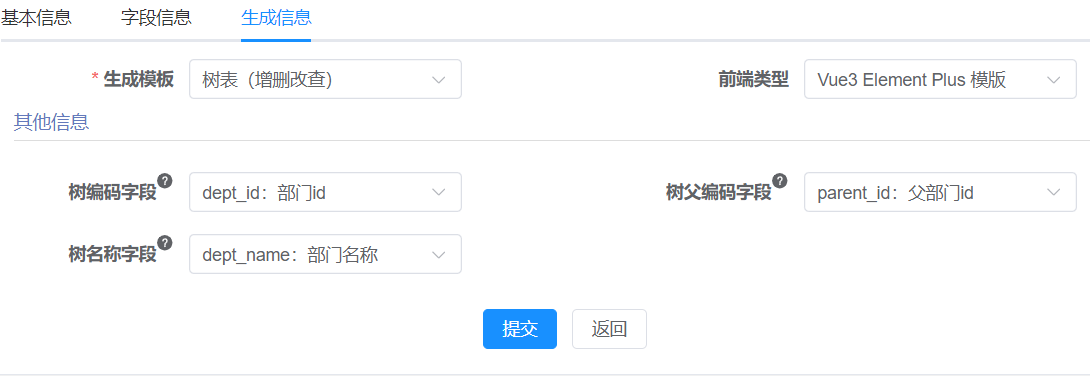


## 系统接口：使用 Swagger 阅读与调试 API

课件第 48 页使用 Swagger 自动生成 API 在线文档，并提供请求调试界面。文档把请求方法、路径、参数和响应结构集中展示，适合在页面开发前确认后端契约。

跟踪课程列表接口时，先确认 `GET /course/course/list`，再核对分页参数和课程查询条件，最后检查响应中的 `rows`、`total`、`code`、`msg`。

**补充：**带权限的接口需要有效身份。通过系统“接口文档 / 系统接口”菜单进入当前版本的文档页面，按项目配置携带令牌；未登录与权限不足分别对应身份校验和授权校验。测试新增、修改、删除时，使用可识别的测试数据，并通过页面和数据库核对结果。


## 后端模块：按职责寻找代码

工程中模块较多时，先判断问题属于启动入口、通用能力、框架机制还是业务功能。课件第 52—58 页按职责介绍后端结构：

| 模块 | 主要职责 | 查找示例 |
| --- | --- | --- |
| `ruoyi-admin` | 后台服务入口、Controller、运行配置 | `RuoYiApplication`、Web 接口 |
| `ruoyi-common` | 公共类与工具 | 注解、常量、异常、工具、基础响应对象 |
| `ruoyi-framework` | 框架核心机制 | 安全、数据源、AOP、异步处理、Web 配置 |
| `ruoyi-system` | 系统业务模块 | 用户、角色、菜单等 Domain / Mapper / Service |
| `ruoyi-generator` | 代码生成 | 生成元数据、模板与生成流程 |
| `ruoyi-quartz` | 定时任务 | 任务配置、调度、执行日志 |

公共模块中的目录：`annotation` 自定义注解，`config` 配置，`constant` 常量，`core` 核心基础类，`enums` 枚举，`exception` 异常，`filter` 过滤器，`utils` 工具，`xss` 输入校验相关功能。

框架模块中的目录：`aspectj` 切面，`config` 配置，`datasource` 多数据源，`interceptor` 拦截器，`manager` 异步管理，`security` 安全，`web` Web 层能力。**AOP 切面**将日志、权限等公共行为集中到方法周围执行。

**整理示例：依赖阅读时的思路，实际直接依赖以各模块 `pom.xml` 为准。**

```text
ruoyi-admin（启动并装配功能）
├─ ruoyi-framework（框架机制）
├─ ruoyi-generator（可选的代码生成功能）
└─ ruoyi-quartz（可选的任务功能）

系统与框架代码复用 ruoyi-system、ruoyi-common 等模块中的能力
```

课件把生成和定时任务标注为“可移除”。移除前需同步检查 Maven 依赖、启动配置、菜单和被引用类，避免只删除模块目录造成编译错误。


## 后端配置文件：连接与行为放在哪里

课件第 56 页以 `ruoyi-admin/src/main/resources` 为入口，说明配置文件的分工：

| 文件或目录 | 职责 | 常见修改 |
| --- | --- | --- |
| `application.yml` | 后端核心配置 | 端口、Redis、MyBatis 路径等 |
| `application-druid.yml` | 数据源与 Druid 配置 | MySQL 地址、账号密码 |
| `mybatis/` | MyBatis 相关配置 | 映射与框架参数 |
| `i18n/` | 国际化消息 | 不同语言的提示文字 |
| `META-INF/` | 项目元信息 | 通常先保留原配置 |
| `banner.txt` | 启动时打印的图案 | 项目启动标识 |
| `logback.xml` | 日志输出配置 | 输出位置、格式和级别 |

配置生效取决于**当前 profile** 和加载顺序。改完数据库文件仍连接旧库时，先确认正在运行哪个实例、加载哪个配置，检查环境变量或启动参数是否覆盖。

**补充：**业务模块新增 Mapper XML 后，要核对 `mybatis.mapperLocations` 是否覆盖该资源路径；新增实体包后，还要核对扫描范围和类型别名配置。页面标题则主要属于前端配置，不能仅靠修改后端项目名称完成。


## 前端结构：API、页面、路由与入口

课件第 60—61 页展示 Vue3 工程。优先从 `src/api` 和 `src/views` 找到业务入口，再顺着调用读公共工具。

```text
RuoYi-Vue3/
├─ package.json             项目信息、依赖、运行脚本
├─ vite.config.js           开发服务器、插件、代理等
├─ .env.development         开发环境变量
├─ .env.production          生产环境变量
├─ .env.staging             预发布环境变量
├─ public/                  直接发布的静态文件
├─ node_modules/            安装的依赖
└─ src/
   ├─ api/                  HTTP API 封装
   ├─ assets/               图片、字体等资源
   ├─ components/           通用组件
   ├─ router/               路由配置
   ├─ utils/                公共工具，如 request.js
   ├─ views/                页面组件
   ├─ App.vue               根组件
   └─ main.js               应用入口与初始化
```

| 要做的事 | 优先查找 |
| --- | --- |
| 修改课程管理布局 | `src/views/course/course/index.vue` |
| 修改课程请求路径或方法 | `src/api/course/course.js` |
| 检查请求拦截器、令牌和错误处理 | `src/utils/request.js` |
| 检查页面路由与菜单加载 | `src/router` 和权限相关代码 |
| 修改本地开发代理 | `vite.config.js` |
| 修改应用标题等环境参数 | `.env.*` 和对应读取代码 |

课件采用 Vite。使用其他版本时可能出现 `vue.config.js` 等文件，先确认当前工程的构建工具，再修改对应配置。


## 数据库表速查：生成配置与业务记录的区别

第 63 页汇总若依系统表。先按功能识别表，能避免把业务记录误当成生成器配置。

| 表 | 说明 | 所属能力 |
| --- | --- | --- |
| `gen_table` | 代码生成业务表元数据 | 生成器 |
| `gen_table_column` | 生成字段元数据 | 生成器 |
| `sys_dict_type` | 字典类型 | 字典 |
| `sys_dict_data` | 字典数据 | 字典 |
| `sys_job` | 任务调度配置 | 定时任务 |
| `sys_job_log` | 任务执行日志 | 定时任务 |
| `sys_logininfor` | 系统访问记录 | 登录日志 |
| `sys_oper_log` | 操作记录 | 操作日志 |
| `sys_notice` | 通知公告 | 系统管理 |
| `sys_config` | 参数配置 | 系统管理 |
| `sys_menu` | 菜单、按钮权限 | 权限 |
| `sys_dept` | 部门 | 组织与权限 |
| `sys_post` | 岗位 | 组织与权限 |
| `sys_role` | 角色 | 权限 |
| `sys_role_dept` | 角色—部门关系 | 数据范围 |
| `sys_role_menu` | 角色—菜单关系 | 功能授权 |
| `sys_user` | 用户 | 账号 |
| `sys_user_post` | 用户—岗位关系 | 组织 |
| `sys_user_role` | 用户—角色关系 | 功能授权 |

`gen_table` 和 `gen_table_column` 保存“怎么生成代码”的配置；`tb_course` 保存真实课程记录。修改生成配置后还需生成或手工修改程序，已经运行的代码不会自动变化。`sys_menu` 决定菜单与权限配置，页面布局则在 Vue 文件中。


## 前端源码：页面状态与 API 封装

课件第 66 页给出课程模块两个主要入口：`api/course/course.js` 与 `views/course/course/index.vue`。页面负责筛选、表格、分页和弹窗；API 文件负责调用后端。

下面是依据课件接口整理的列表请求片段，调用项目已有的 Axios 工具：

```javascript
// src/api/course/course.js —— 整理示例
import request from '@/utils/request'

export function listCourse(query) {
  return request({
    url: '/course/course/list',
    method: 'get',
    params: query
  })
}
```

**补充：Vue3 页面列表逻辑的简化示例。**完整页面仍需查询控件、表格与分页组件：

```javascript
import { reactive, ref } from 'vue'
import { listCourse } from '@/api/course/course'

const queryParams = reactive({
  pageNum: 1,
  pageSize: 10,
  code: undefined,
  subject: undefined,
  name: undefined,
  applicablePerson: undefined
})
const courseList = ref([])
const total = ref(0)
const loading = ref(false)

async function getList() {
  loading.value = true
  try {
    const response = await listCourse(queryParams)
    courseList.value = response.rows
    total.value = response.total
  } finally {
    loading.value = false
  }
}

function handleQuery() {
  queryParams.pageNum = 1
  return getList()
}
```

改变筛选条件后重置 `pageNum=1`，否则原来的后几页可能在新条件下没有数据。`finally` 保证请求失败时也能解除加载状态；错误提示沿用项目请求工具的统一处理方式。


## 后端源码：Controller、Service、Mapper 与实体

课件第 68 页的课程代码沿经典分层组织。先从请求入口看业务调用，再查看 SQL。

| 类或文件 | 职责 | 阅读时关注 |
| --- | --- | --- |
| `CourseController` | 接收 HTTP 请求并返回响应 | 路径、参数、权限、分页与响应 |
| `ICourseService` | 定义业务方法 | 对外提供什么操作 |
| `CourseServiceImpl` | 实现业务流程 | 校验、事务、调用 Mapper |
| `CourseMapper` | 定义数据库访问方法 | 方法参数与返回类型 |
| `CourseMapper.xml` | SQL 和结果映射 | 查询条件、字段映射、表名 |
| `Course` | 课程数据对象 | 属性、注解和公共字段 |

```text
CourseController.list(course)
  → CourseServiceImpl.selectCourseList(course)
    → CourseMapper.selectCourseList(course)
      → CourseMapper.xml 中的 SELECT
        → MySQL.tb_course
```

**补充：**简单 CRUD 的 Service 可能只转调 Mapper，但涉及唯一性、状态变更和跨表保存时，应在业务层集中校验与事务。Mapper XML 的 `namespace` 要匹配接口全限定名，SQL 的 `id` 要匹配方法名；不一致常表现为找不到绑定语句。


## BaseController 与分页机制

课件第 69—70 页把公共 Web 处理抽到 `BaseController`：分页、响应转换、当前登录用户等。课程 Controller 继承它后可调用这些方法。

| 方法 | 作用 |
| --- | --- |
| `startPage()` | 根据请求中的分页参数启动分页 |
| `getDataTable(list)` | 将结果包装为表格分页响应 |
| `toAjax(rows)` | 根据影响行数等结果生成操作响应 |
| `success()` / `error()` | 生成通用成功或失败响应 |
| `getLoginUser()` | 获取当前登录用户对象 |
| `getUserId()` / `getDeptId()` / `getUsername()` | 获取用户 ID、部门 ID、用户名 |

课件第 73、78 页的代码，按原语义排版：

```java
@PreAuthorize("@ss.hasPermi('course:course:list')")
@GetMapping("/list")
public TableDataInfo list(Course course) {
    startPage();
    List<Course> list = courseService.selectCourseList(course);
    return getDataTable(list);
}
```

**补充：**这类若依版本通常通过 PageHelper 拦截 MyBatis 查询实现分页。`startPage()` 从请求读取 `pageNum`、`pageSize` 等信息，分页设置作用于当前线程中随后执行的查询。应紧接着执行目标列表查询，避免无关查询先消耗分页设置。

```java
// 错误顺序：列表已查出后，再开启分页
List<Course> list = courseService.selectCourseList(course);
startPage();

// 正确顺序：先设置分页，再执行目标查询
startPage();
List<Course> list = courseService.selectCourseList(course);
```

`rows` 是当前页记录，`total` 是符合条件的总记录数。把 `total` 写成 `rows.size()` 会让分页器误认为只有当前页。


## TableDataInfo、AjaxResult 与响应契约

分页列表和单次操作需要的字段不同。课件第 70—71 页使用两种响应对象：

| 对象 | 用途 | 响应字段 |
| --- | --- | --- |
| `TableDataInfo` | 表格分页 | `total`、`rows`、`code`、`msg` |
| `AjaxResult` | 详情、保存、删除等结果 | `code`、`msg`，可带 `data` |

**课件方案：**`TableDataInfo` 具有 `long total`、`List<?> rows`、`int code`、`String msg`。`AjaxResult` 继承 `HashMap<String,Object>`，用 `CODE_TAG`、`MSG_TAG`、`DATA_TAG` 统一键名。

整理后的分页响应示例，`total` 大于本页行数是正常情况：

```json
{
  "total": 6,
  "rows": [
    {
      "id": 1,
      "code": "cp123456",
      "subject": "0",
      "name": "JavaSE基础",
      "price": 199,
      "applicablePerson": "小白学员",
      "info": "JavaSE基础"
    }
  ],
  "code": 200,
  "msg": "查询成功"
}
```

详情响应通常从 `data` 中取对象；操作响应可只包含 `{"code":200,"msg":"操作成功"}`。前端读分页结果时使用 `response.rows` 和 `response.total`，不能套用详情接口的读取方式。

**补充：**JSON 中的 `code` 是项目业务状态码，HTTP 状态码属于协议层。调试时分别查看两者；HTTP 成功返回也可能包含业务失败信息。


## BaseEntity：公共字段与 JSON 注解

课件第 72 页的 `BaseEntity` 集中放置创建、更新、备注等字段，业务实体按需要继承它，减少重复声明。

**课件字段与注解，省略 getter / setter：**

```java
public class BaseEntity implements Serializable {
    @JsonIgnore
    private String searchValue;

    private String createBy;

    @JsonFormat(pattern = "yyyy-MM-dd HH:mm:ss")
    private Date createTime;

    private String updateBy;

    @JsonFormat(pattern = "yyyy-MM-dd HH:mm:ss")
    private Date updateTime;

    private String remark;

    @JsonInclude(JsonInclude.Include.NON_EMPTY)
    private Map<String, Object> params;
}
```

| 项目 | 含义 |
| --- | --- |
| `Serializable` | Java 对象可进行序列化 |
| `@JsonIgnore` | Jackson 转换 JSON 时忽略该属性 |
| `@JsonFormat` | 指定日期的 JSON 格式 |
| `@JsonInclude(NON_EMPTY)` | 空的参数集合不写入 JSON |
| `params` | 扩展查询参数，如时间区间 |

**补充：**继承 `BaseEntity` 只增加 Java 属性，不会自动增加数据库列或自动写入审计值。本例 `tb_course` 没有 `create_by`、`update_by`、`remark` 列，SQL 应按实际表结构映射；创建时间与更新时间仍需插入、更新逻辑提供。


## @PreAuthorize：接口执行前检查权限

课件第 73—74 页说明 Spring Security 在业务方法运行前验证权限。以课程列表为例：

```java
@PreAuthorize("@ss.hasPermi('course:course:list')")
```

表达式中的 `@ss` 指向 Spring 容器内的权限服务 Bean；`hasPermi` 校验当前登录用户是否拥有指定权限字符串。

```text
登录 → 获得用户基本信息、角色集合、权限集合
请求课程列表 → 读取当前登录身份 → 执行权限表达式
  ├─ 包含 course:course:list → 执行列表查询
  └─ 未包含该权限 → 返回权限不足
```

**补充：**认证解决“是谁”，授权解决“可以做什么”。JWT / 登录状态建立身份，角色与权限集合用于授权。实际工程中的权限服务可能支持超级管理员、通配权限等特殊规则，要沿 `ss` Bean 的实现确认。

排查权限不足时，依次核对后端注解、`sys_menu.perms`、角色菜单关系、用户角色关系，以及当前登录用户的权限集合。权限调整后，若会话仍使用旧信息，可重新登录验证，并核对该版本的刷新机制。

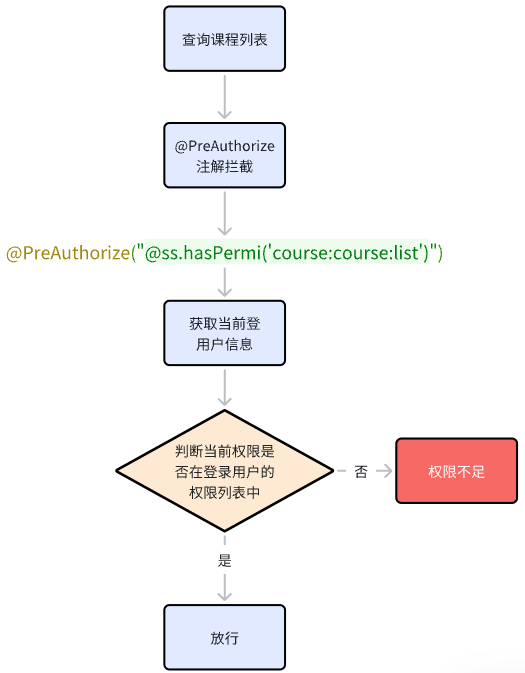


## 课程列表接口：请求参数与响应字段

课件第 76—78 页用课程列表连接前后端。接口契约明确后，才能判断请求失败是字段、身份、权限、分页还是 SQL 问题。

| 项目 | 课件内容 |
| --- | --- |
| 请求方法 | `GET` |
| 业务路径 | `/course/course/list` |
| 分页参数 | `PageDomain` 对应的查询参数 |
| 业务参数 | `Course` 对应的课程查询条件 |
| 响应类型 | `TableDataInfo` |
| 所需权限 | `course:course:list` |

**整理示例：**

```http
GET /course/course/list?pageNum=1&pageSize=10&subject=0&name=Java
```

GET 参数放在 URL 查询字符串中。`pageNum` 和 `pageSize` 由分页工具读取；`subject`、`name` 等绑定到 `Course`。中文参数由请求工具编码。

```text
课程页面 getList()
  → listCourse(queryParams)
  → request.js / Axios
  → Vite 开发代理
  → 后端身份与权限检查
  → CourseController.list()
  → startPage() → Service → Mapper → MySQL
  → getDataTable(list)
  → 前端取 rows、total → 更新表格和分页器
```

课件响应中的课程属性包含 `id`、`code`、`subject`、`name`、`applicablePerson`、`info` 等；价格和公共时间字段也见第 70 页截图。顶层 `code` 表示结果状态，而 `rows[i].code` 表示课程编码，两者处于不同层级。


## Axios 拦截器：统一处理令牌和返回结果

课件第 77 页将 Axios 工具分为请求拦截器和响应拦截器。**拦截器**是在请求发送前或响应返回后统一执行的函数，避免每个 API 重复处理公共行为。

| 位置 | 常见职责，具体以 request.js 为准 |
| --- | --- |
| Axios 实例 | 设置基础路径、超时等 |
| 请求拦截器 | 携带登录令牌，处理公共请求参数 |
| 响应拦截器 | 识别业务状态、统一提示和登录失效处理 |
| 业务页面 | 使用本次请求的 rows、total 或 data |

**补充：请求拦截器的机制片段。**若依项目已有实现时，应沿用它，下面用于理解令牌如何进入请求头：

```javascript
service.interceptors.request.use(config => {
  const token = getToken()
  if (token) {
    config.headers.Authorization = `Bearer ${token}`
  }
  return config
})
```

身份令牌不是业务查询字段。浏览器 Network 中应检查实际请求头、URL 与返回数据；从 API 包装方法返回的内容，也要以当前响应拦截器的处理方式为准。若它已返回 JSON 主体，再额外读取 Axios 的 `.data` 就可能取错层级。

**补充：**课件所用若依版本通常结合 JWT 和 Redis 登录信息处理会话。JWT 的格式不能证明当前登录状态始终有效，仍需由服务端校验与当前会话逻辑判断。


## /dev-api 代理：浏览器地址与后端地址的区别

第 78—79 页展示两个地址：浏览器请求 `http://localhost/dev-api/course/course/list`，后端实际处理 `http://localhost:8080/course/course/list`。

```text
业务 API：       /course/course/list
Axios 基础路径： /dev-api
浏览器请求：     http://localhost/dev-api/course/course/list
Vite 代理：      去掉 /dev-api，再转发到 http://localhost:8080
后端收到：      /course/course/list
```

课件代理配置按可运行语法整理如下，合并到已有 `vite.config.js` 中：

```javascript
// 整理示例：实际 listen 端口、配置结构以项目为准
server: {
  proxy: {
    '/dev-api': {
      target: 'http://localhost:8080',
      changeOrigin: true,
      rewrite: path => path.replace(/^\/dev-api/, '')
    }
  }
}
```

> **勘误：**第 79 页代码使用了不匹配的中文引号，JavaScript 中应写成成对的英文引号。`rewrite` 删除的是路径最前面的 `/dev-api`，后端 Controller 无需增加该前缀。

| 错误配置 | 结果 | 正确思路 |
| --- | --- | --- |
| API 方法与基础路径各添加一次 `/dev-api` | 请求出现重复前缀 | API 中保留业务路径 |
| 保留前缀且后端没有相应路径 | 后端可能返回 404 | 代理重写为实际业务路径 |
| target 指向错误端口 | 代理连接失败或进入其他服务 | 与后端启动日志一致 |

**补充：**浏览器请求 Vite 同源地址，再由 Vite 访问后端，可以避免本地开发中的跨域问题。`changeOrigin` 调整代理转发时的请求主机信息；开发代理只在开发服务器中生效。生产部署需要另行配置 Nginx / 网关转发与前端 API 基础路径。


## 项目改名：从若依工程到外卖管理系统

课件第 82 页使用[若依框架修改器](https://gitee.com/lpf_project/RuoYi-MT/releases)批量修改项目名、包名和 Maven 标识。

| 项目 | 原值 | 课件目标 |
| --- | --- | --- |
| 目录 / 项目名称 | RuoYi / ruoyi | `sky` |
| Java 包名 | `com.ruoyi` | `com.sky` |
| groupId | `com.ruoyi` | `com.sky` |
| artifactId 前缀 | `ruoyi` | `sky` |
| 站点名称 | 若依管理系统 | 外卖管理系统 |

修改后出现 `sky-admin`、`sky-common`、`sky-framework`、`sky-generator`、`sky-quartz`、`sky-system` 等模块。

**补充：**改名结果需要核对 Java 的 `package` / `import`、Spring 扫描包、Mapper XML 的 `namespace` 和类型引用、Maven 父子坐标、依赖版本及资源路径。先保留可回退的代码版本，再确认编译、启动、登录和已有课程功能。

前端 Vue3 工程与后端可以是两个独立目录。工具修改后端项目标识后，前端标题、Logo 和登录背景仍需单独检查。


## 新建业务模块：sky-merchant 与 Maven 依赖

课件第 83 页新增 `sky-merchant` 管理商家业务，避免将所有新增功能继续堆在启动模块中。顺序为：新建子模块 → 父工程锁定版本 → `sky-admin` 添加依赖。

**整理示例：在父工程 pom.xml 的已有配置中分别追加。**`${sky.version}` 是课件截图使用的版本属性，应由父工程现有配置定义：

```xml
<!-- modules：让 Maven 聚合构建这个模块 -->
<modules>
    <!-- 保留原有模块 -->
    <module>sky-merchant</module>
</modules>

<!-- dependencyManagement：统一版本，不会自动引入依赖 -->
<dependencyManagement>
    <dependencies>
        <!-- 保留原有条目 -->
        <dependency>
            <groupId>com.sky</groupId>
            <artifactId>sky-merchant</artifactId>
            <version>${sky.version}</version>
        </dependency>
    </dependencies>
</dependencyManagement>
```

`sky-merchant/pom.xml` 继承父工程并声明自身 `artifactId`。第 83 页截图选择 Java 11，依赖框架模块：

```xml
<!-- 子模块中需要的依赖片段 -->
<dependencies>
    <dependency>
        <groupId>com.sky</groupId>
        <artifactId>sky-framework</artifactId>
    </dependency>
</dependencies>
```

在 `sky-admin/pom.xml` 中引入业务模块：

```xml
<dependency>
    <groupId>com.sky</groupId>
    <artifactId>sky-merchant</artifactId>
</dependency>
```

| Maven 配置 | 作用 |
| --- | --- |
| `<modules>` | 定义父工程聚合构建哪些子模块 |
| `<dependencyManagement>` | 统一依赖版本等规则 |
| `<dependencies>` | 实际将依赖加入当前模块 |

```text
sky-admin → sky-merchant → sky-framework → 已有基础能力
```

**补充：**依赖业务模块后，其中的 Controller / Service 还需被 Spring 扫描，Mapper 接口和 XML 也需被加载。包名位于 `com.sky` 范围内时，应与项目已有扫描规则核对。修改完成后从父工程构建，确保父子坐标与版本都能解析。


## 菜品主子表：一份菜品带多条口味

课件第 85—86 页用**菜品—口味**演示主子表生成。一个菜品可以包含“忌口”“辣度”等多条口味记录，每条子记录通过 `dish_id` 指向主菜品。

| 表 | 字段 | 类型与含义 |
| --- | --- | --- |
| `tb_dish` | `id` | bigint，菜品主键 |
| `tb_dish` | `name` | varchar(32)，菜品名称 |
| `tb_dish` | `price` | decimal(10,2)，菜品价格 |
| `tb_dish` | `image` | varchar(255)，图片 |
| `tb_dish` | `description` | varchar(255)，描述信息 |
| `tb_dish` | `status` | int，0 停售、1 起售 |
| `tb_dish` | `create_time` / `update_time` | datetime，创建 / 更新时间 |
| `tb_dish_flavor` | `id` | bigint，口味主键 |
| `tb_dish_flavor` | `dish_id` | bigint，关联菜品 ID |
| `tb_dish_flavor` | `name` | varchar(32)，口味名称 |
| `tb_dish_flavor` | `value` | varchar(255)，口味选项列表的存储值 |

```text
tb_dish.id = 1（毛血旺）
  ├─ tb_dish_flavor：dish_id=1，name=忌口，value=["不要蒜","不要香菜"]
  └─ tb_dish_flavor：dish_id=1，name=辣度，value=["微辣","中辣"]
```

下面按截图重建 DDL，**自增、空值、默认值和关联索引属于整理选择**。课件没展示完整 SQL，不将该片段视为原始脚本：

```sql
CREATE TABLE tb_dish (
    id BIGINT NOT NULL AUTO_INCREMENT COMMENT '主键',
    name VARCHAR(32) COMMENT '菜品名称',
    price DECIMAL(10,2) COMMENT '菜品价格',
    image VARCHAR(255) COMMENT '图片',
    description VARCHAR(255) COMMENT '描述信息',
    status INT DEFAULT 1 COMMENT '0停售 1起售',
    create_time DATETIME COMMENT '创建时间',
    update_time DATETIME COMMENT '更新时间',
    PRIMARY KEY (id)
) ENGINE=InnoDB DEFAULT CHARSET=utf8mb4 COMMENT='菜品管理';

CREATE TABLE tb_dish_flavor (
    id BIGINT NOT NULL AUTO_INCREMENT COMMENT '主键',
    dish_id BIGINT COMMENT '菜品ID',
    name VARCHAR(32) COMMENT '口味名称',
    value VARCHAR(255) COMMENT '口味选项列表',
    PRIMARY KEY (id),
    KEY idx_dish_id (dish_id)
) ENGINE=InnoDB DEFAULT CHARSET=utf8mb4 COMMENT='菜品口味关系表';
```

**补充：**Java 价格采用 `BigDecimal`。子表通过 `dish_id` 建立逻辑关系，上述示例没有物理外键；实际业务需保证引用有效。选项列表存为字符串时，要统一其 JSON 格式和长度约束。

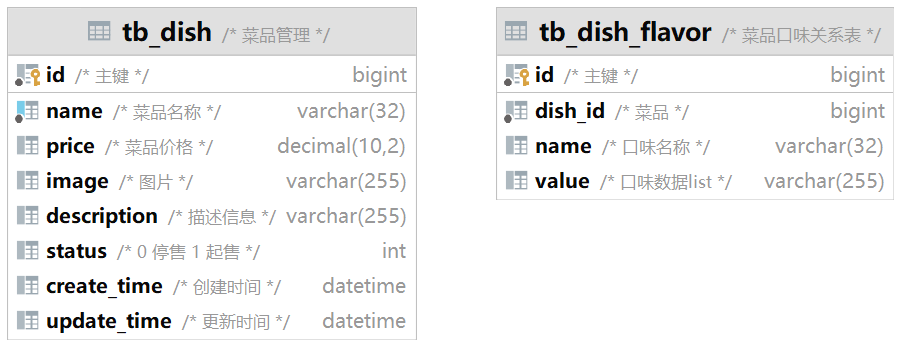


## 主子表生成：字段配置、路径与事务

第 86 页操作顺序：导入两张表 → 配置代码生成 → 下载并导入 → 升级改造。

| 配置 | 课件案例对应关系 |
| --- | --- |
| 主表 | `tb_dish`，实体 `Dish` |
| 子表 | `tb_dish_flavor`，实体 `DishFlavor` |
| 生成模板 | 主子表 |
| 子表关联字段 | `dish_id`，对应主表 `id` |
| 后端包路径 | `com.sky.merchant` |
| 前端 API | `src/api/merchant/dish.js` |
| 前端页面 | `src/views/merchant/dish/index.vue` |
| Mapper XML | `sky-merchant/src/main/resources/mapper/merchant/DishMapper.xml` |

确认生成产物包含主表实体、子表实体及主对象中的明细列表，复制至 `sky-merchant`，再导入前端与菜单 SQL。

**补充：主子表保存的逻辑顺序。**具体方法以生成结果为准：

```text
新增：校验 → 插入菜品 → 获取生成的菜品ID → 回填每条口味的dishId → 保存口味
修改：校验 → 更新菜品 → 按业务规则更新口味明细
删除：校验 → 删除口味明细与菜品，防止遗留孤立记录
```

部分生成模板采用“删除旧子项，再批量插入新子项”的方式处理修改。阅读 Service 代码后再确定采用的策略，核对新增行、删除行和明细主键的行为。

两张表应在**同一个事务**中保存：事务将一组数据库操作作为整体，任一步失败都回滚，避免出现菜品已保存但口味丢失的状态。

```java
// 补充示例：方法内具体保存逻辑由项目实现
@Transactional(rollbackFor = Exception.class)
public int saveDishWithFlavors(Dish dish) {
    // 校验数据、保存主表、保存子表
    return saveDishAndFlavors(dish);
}
```

上面为机制片段，`saveDishAndFlavors` 是示意方法。真正实现时，要确认 Spring 事务代理生效、使用可支持事务的表引擎，并校验价格、状态、口味重复和选项长度。


## 菜品页面升级：图片上传与口味多选

第 85、86 页对比了生成表单和改造后的表单：图片字段改为上传与预览，口味名称改为可选择项，选项值改为多选。生成代码提供基础结构，交互与数据格式仍需业务适配。

| 字段 | 原始形式 | 改造要点 |
| --- | --- | --- |
| `image` | 字符串输入 | 使用上传组件，保存上传后返回的地址或路径 |
| `status` | 普通输入 | 显示起售 / 停售，与 1 / 0 对应 |
| 口味 `name` | 文本输入 | 选项名称与可选值联动 |
| 口味 `value` | 字符串输入 | 页面使用数组，提交前转换为约定格式 |
| `price` | 数值输入 | 统一小数位、非负规则和接口类型 |

**补充：口味多选值与字符串存储的转换示例。**页面使用独立的 `selectedValues` 状态，避免同一个字段一会儿是数组、一会儿是字符串：

```javascript
// 详情接口返回的 flavor.value 是 JSON 字符串
function toFlavorForm(flavor) {
  const values = flavor.value ? JSON.parse(flavor.value) : []
  if (!Array.isArray(values) || values.some(v => typeof v !== 'string')) {
    throw new Error('口味选项格式不正确')
  }
  return { ...flavor, selectedValues: values }
}

// 提交时恢复为后端约定的字符串字段
function toFlavorPayload(formRow) {
  const { selectedValues, ...flavor } = formRow
  return { ...flavor, value: JSON.stringify(selectedValues ?? []) }
}
```

调用处需要处理无效 JSON，并向用户提示数据异常。新增、修改回显、再次保存都应保持同一种转换规则；切换口味名称后，清理不属于新选项集的旧值。

图片上传还需核对组件的 `v-model` 类型、上传地址、请求令牌、返回字段和详情回显。第 85 页示例界面限制文件大小为 5 MB，并提示 `png/jpg/jpeg` 格式；真实限制应同时在前后端实现。新增主子表时，要通过实际网络响应和数据库验证两表内容都正确。

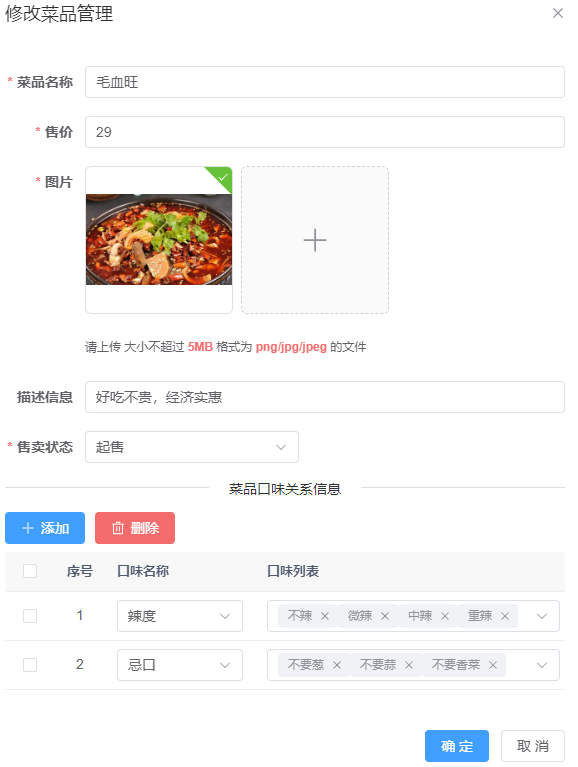


## AI 辅助改造：把上下文和验收条件写进提示词

第 86 页展示通义灵码作为代码辅助工具，未给出具体提示词。让 AI 改造若依页面时，需要同时提供组件约定、接口契约和存储格式，才能减少生成代码与现有工程的冲突。

**补充提示词，非课件原文：**

```text
这是一个 RuoYi-Vue 的菜品管理模块，前端使用 Vue3、Element Plus。
请先阅读 merchant/dish/index.vue、api/merchant/dish.js、现有图片上传组件，
以及 Dish、DishFlavor 和保存接口，再给出修改方案并实现。

需求：
1. 保持现有 API 路径、权限标识和主子表保存流程。
2. 图片使用项目已有上传组件，按其真实绑定值和返回格式处理，支持编辑回显。
3. 口味名称改为选择框；选项值改为多选。
4. 页面多选值用数组，后端 DishFlavor.value 按接口约定保留 JSON 字符串。
5. 新增、详情回显、修改提交采用一致转换，不向后端额外提交临时页面字段。
6. 沿用现有校验与错误提示方式，列出修改文件及数据转换的位置。

验收：
新增菜品带两组口味，刷新后编辑能够完整回显；
删除一行口味再保存，数据库中不存在被删除的旧记录；
上传图片后保存并重新打开，图片仍正确显示；
普通用户的权限控制保持有效。
```

判断 AI 结果时，沿请求链路检查真实输入输出：多选组件交付的数组是否正确转换，提交中是否含有主记录与口味列表，后端是否在事务中维护明细。提示词清楚后，仍需运行和检查实际结果。


## 页面定制：标题、Logo、图标、主题与登录页

课件第 88—89 页把若依界面调整为外卖管理系统的标识。定制包含多个显示位置，需要逐项核对。

| 课件要求 | 补充：Vue3 工程中的常见查找位置 |
| --- | --- |
| 浏览器标签页 icon、标题 | `public/favicon.ico`、`index.html`、`.env.*`、动态标题工具 |
| 系统页面 Logo、标题 | `src/assets/logo/`、侧栏 Logo 组件、`settings.js` 等 |
| 去除“源码 / 文档”入口 | 导航栏组件及对应按钮组件 |
| 主题与自定义图标 | 设置配置、样式、`src/assets/icons/svg` 与图标组件 |
| 登录页标题、背景图 | `src/views/login.vue`、登录背景资源 |

以上文件名是常见定位线索，**具体以当前版本源码为准**。使用搜索查文字或资源引用，能比凭目录猜测更快找到位置。

项目标题可能由环境变量、设置文件与路由动态标题共同决定。修改后分别检查登录页、首页、业务页面和刷新后的浏览器标题。替换 Logo 和背景时核对图片路径、比例与加载结果；自定义 SVG 图标的名称需要与菜单配置一致。

**补充：**课件的“去除源码 / 文档”是调整页面入口。技术文档可以继续在开发环境按需要使用；页面改动后还需保留原项目授权许可要求。

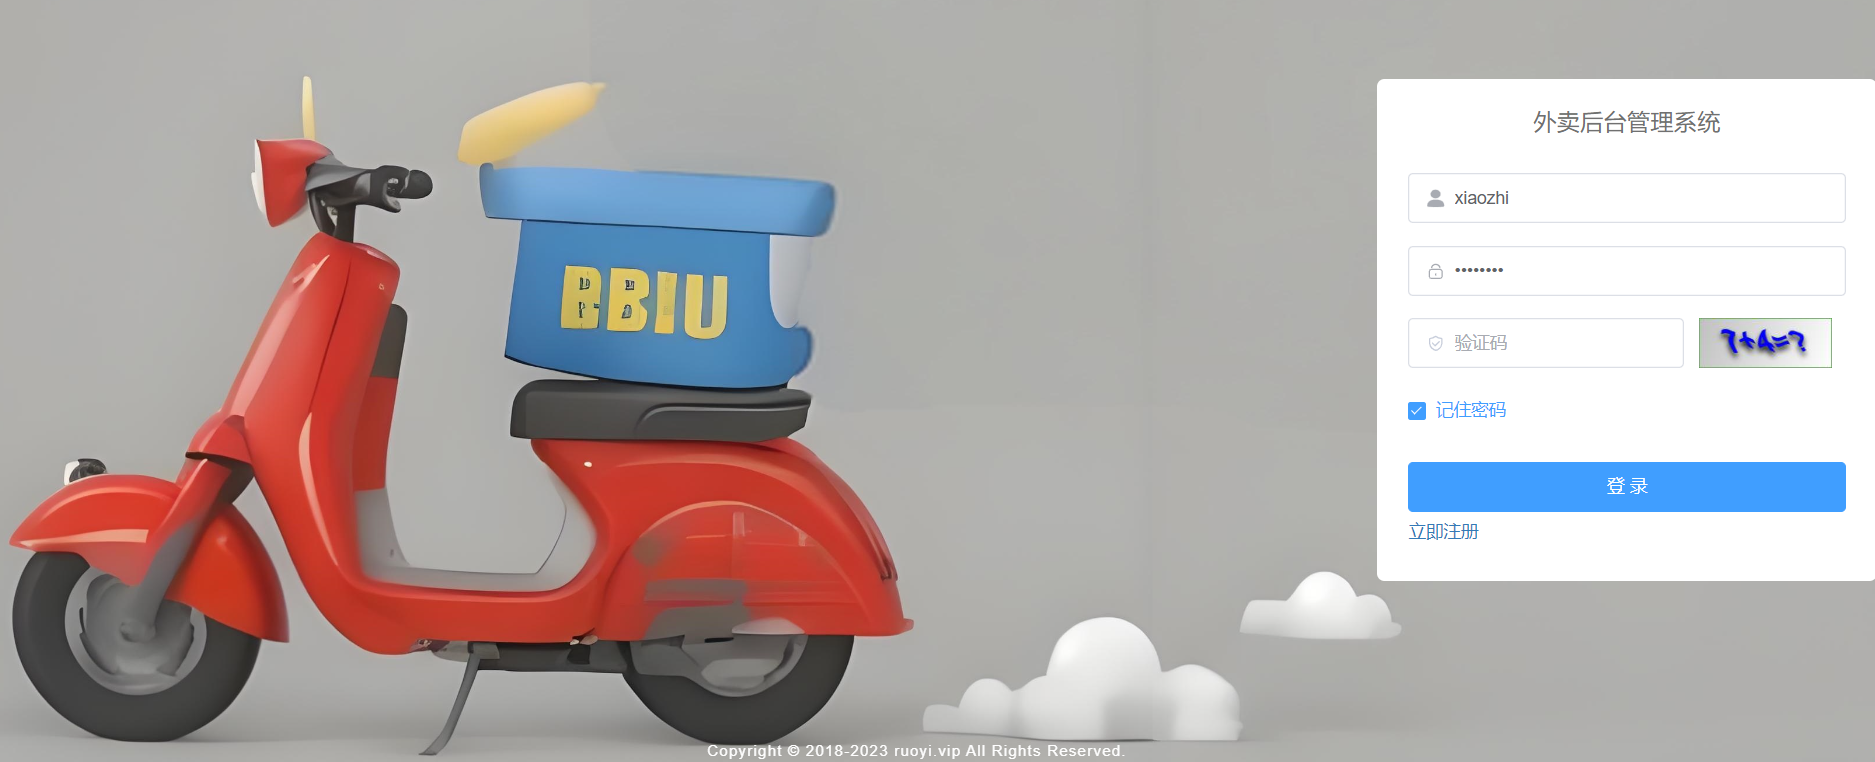


## 本章排查与实践验收

问题按失败位置分类，再检查对应证据，比反复重新生成代码更有效。

| 现象 | 优先检查 |
| --- | --- |
| 前端无法启动 | Node 引擎、依赖安装结果、package.json 脚本 |
| 前端请求 404 | API 业务路径、/dev-api 是否重写、Controller 路径 |
| 代理连接失败 | 后端是否运行、target 主机与端口 |
| 已登录仍权限不足 | 注解字符串、菜单权限、角色授权、当前会话 |
| 菜单显示但页面打不开 | 组件路径、实际 Vue 文件、前端加载错误 |
| 分页返回全部数据 | startPage 顺序、分页参数、分页插件配置 |
| 学科回显为 0 / 1 / 2 | 字典类型、dict-tag、字典数据及缓存 |
| 新业务 Controller 不生效 | admin 依赖、包扫描范围、模块是否进入构建 |
| Mapper 语句找不到 | namespace、方法 ID、XML 路径和扫描规则 |
| 菜品保存后口味缺失 | 明细列表、主键回填、事务及 SQL 执行 |
| 口味多选无法回显 | 字符串 / 数组转换、选项值类型 |
| 定时任务重复执行 | 是否同时用了 Scheduled 和 Quartz，是否重复启用任务 |

完成本篇实践应能做到：

- 后端与 Vue3 前端启动，数据库和 Redis 连接正常。
- 从 `tb_course` 生成并接入页面、接口、Mapper 和菜单。
- 小智只获得设定菜单及对应操作权限，未授权请求被后端拒绝。
- 学科字段通过 `course_subject` 查询、展示、编辑并正确回显。
- 定时任务可启停、按 5 秒规则输出时间并查看日志。
- 解释 `GET /course/course/list` 从 Axios 到 SQL 再到 `rows/total` 的链路。
- `sky-merchant` 被启动模块引入，菜品与口味在事务中完整保存。
- 上传、口味多选和页面标识调整后，刷新及编辑回显正常。


## 高频面试知识点

**面试提示**：本章应能把功能操作与底层机制对应起来，重点说明下面的边界：

| 问题 | 回答要点 |
| --- | --- |
| 前后端分离与微服务有什么关系？ | 分离是浏览器页面和后端接口分工；微服务是后端运行与部署边界。RuoYi-Vue 本课是单体多模块。 |
| RBAC 如何分配权限？ | 用户关联角色，角色关联菜单 / 按钮权限；通过两组关联表表达多对多关系。 |
| 认证、功能权限、数据权限如何区分？ | 身份是否合法；接口能否调用；记录范围是否允许。菜单显示还需配合后端授权。 |
| @PreAuthorize 如何生效？ | 方法执行前由 Spring Security 检查表达式；本例调用 ss Bean 的 hasPermi 校验用户权限。 |
| startPage 为什么要放在查询前？ | 分页插件需要拦截随后执行的目标查询；total 是总记录数，rows 是当前页。 |
| TableDataInfo 与 AjaxResult 怎么选？ | 分页列表返回 rows/total；详情和操作使用 code/msg 及可选 data。 |
| 主子表为什么要用事务？ | 主表与多条子表操作应整体提交或回滚，同时维护主键与关联 ID。 |
| dependencyManagement 会引入模块吗？ | 它统一版本；dependencies 实际引入，modules 负责聚合构建。 |
| /dev-api 为什么没有出现在后端路径里？ | 它是开发请求前缀，Vite 代理重写后将业务路径转发到后端。 |
